# Lab 2 — What Did the Campaign Deliver?
Name: Ivan Morozov | Group: KM-43

## Setup

In [1]:
import kagglehub
import pandas as pd
import matplotlib.pyplot as plt
DATA = kagglehub.dataset_download("shkarupylomaxim/adtech-lab1-tv-panel/versions/3")
programs = pd.read_parquet(f"{DATA}/programs.parquet")
viewings = pd.read_parquet(f"{DATA}/viewings.parquet")
daily_weights = pd.read_parquet(f"{DATA}/daily_weights.parquet")
viewer_attributes = pd.read_parquet(f"{DATA}/viewer_attributes.parquet")
attributes = pd.read_parquet(f"{DATA}/attributes.parquet")
commercials = pd.read_parquet(f"{DATA}/commercials.parquet")
rate_card = pd.read_parquet(f"{DATA}/rate_card.parquet")

Preparation for all tasks:
- persons = R and L, broadcast day = time minus 6 hours
- A18-49 and W18-34 from the exact age (code 300) and sex (code 202 = Female)
- monthly weight = mean of the daily weights of a person
- for every broadcast day: sum of weights and number of in-tab persons, for P2+ and A18-49

In [2]:
import numpy as np

PERSON_TYPES = ["R", "L"]
BIG = ["CBS", "NBC", "ABC", "FOX", "FNC"]
SMALL = ["FX", "BRAVO", "HGTV", "FOOD", "HIST"]


def broadcast_day(ts):
    return (ts - pd.Timedelta(hours=6)).dt.normalize()


# 300 = exact age, 202 = Female (codes from attributes, same as in lab 1)
age = viewer_attributes[viewer_attributes.attr_id == 300].set_index("respondent_id")["value"]
female = viewer_attributes[viewer_attributes.attr_id == 202].respondent_id
# attributes[attributes.attr_id.isin([202, 300])]

pw = daily_weights[daily_weights.resp_type.isin(PERSON_TYPES)].copy()
pw["bday"] = pd.to_datetime(pw.broadcast_date)
pw["age"] = pw.respondent_id.map(age)
pw["a1849"] = pw.age.between(18, 49)
pw["w1834"] = pw.age.between(18, 34) & pw.respondent_id.isin(female)

persons = pw.groupby("respondent_id").agg(mw=("weight", "mean"), a1849=("a1849", "first"),
                                          w1834=("w1834", "first"))
print("Persons:", len(persons), " without age:", pw.age.isna().sum())
print("A18-49 share of persons:", round(persons[persons.a1849].mw.sum() / persons.mw.sum(), 3))

day_p2 = pw.groupby("bday").weight.sum()
day_1849 = pw[pw.a1849].groupby("bday").weight.sum()
day_n = pw.groupby("bday").size()  # n for the SE in task 5

pv = viewings[viewings.resp_type.isin(PERSON_TYPES)]

Persons: 10210  without age: 0
A18-49 share of persons: 0.422


## Task 1.1 — Size

In [3]:
print("Spots:", len(commercials))
print("Pods:", commercials.pod_id.nunique())
print("Brands:", commercials.brand.nunique())
print("Categories:", commercials.category.nunique())
print("BRAND_A spots:", (commercials.brand == "BRAND_A").sum())
commercials[commercials.brand == "BRAND_A"].network_code.value_counts().rename("BRAND_A spots")

Spots: 167720
Pods: 22359
Brands: 95
Categories: 14
BRAND_A spots: 300


network_code
FNC      40
HGTV     39
FX       38
HIST     37
BRAVO    33
FOOD     33
ABC      29
CBS      22
NBC      16
FOX      13
Name: BRAND_A spots, dtype: int64

In [4]:
commercials.groupby("category").agg(spots=("ad_airing_id", "size"), brands=("brand", "nunique"))

,spots,brands
category,,
AUTO,21142,10
BEVERAGE,9297,6
FINANCE,8148,6
FOOD,13368,12
INSURANCE,16325,6
PHARMA,22698,14
POLITICAL,6143,4
PROMO,15161,3
QSR,12801,8


## Task 1.2 — Ad load

In [5]:
ads = commercials.copy()
ads["hour"] = ads.start_ts.dt.floor("h")
per_hour = ads.groupby(["network_code", "hour"]).length_sec.sum().reset_index()

load = per_hour.groupby("network_code").agg(hours_with_ads=("hour", "size"), ad_sec=("length_sec", "mean"))
load["ad_min_per_hour"] = load.ad_sec / 60
load["hours_without_ads"] = 31 * 24 - load.hours_with_ads
load = load.drop(columns="ad_sec").sort_values("ad_min_per_hour", ascending=False)
print(load.round(1))
print("Heaviest ad load:", load.ad_min_per_hour.idxmax())

              hours_with_ads  ad_min_per_hour  hours_without_ads
network_code                                                    
FNC                      743             15.6                  1
BRAVO                    623             13.4                121
HGTV                     621             13.3                123
HIST                     622             13.2                122
FOOD                     620             13.1                124
FX                       621             12.9                123
CBS                      427             12.1                317
ABC                      349             11.8                395
NBC                      299             11.8                445
FOX                      196             11.8                548
Heaviest ad load: FNC


In [6]:
no_ads = programs[~programs.telecast_id.isin(commercials.telecast_id)]
hours = no_ads.pivot_table(index="network_code", columns="program_type", values="duration_min",
                           aggfunc="sum", fill_value=0) / 60
hours[["local", "paid programming", "special"]].round(1)

program_type,local,paid programming,special
network_code,,,
ABC,438.2,0.0,1.8
BRAVO,0.0,124.0,0.0
CBS,363.1,0.0,1.8
FNC,0.0,0.0,1.8
FOOD,0.0,124.0,0.0
FOX,561.1,0.0,0.0
FX,0.0,124.0,0.0
HGTV,0.0,124.0,0.0
HIST,0.0,124.0,0.0


**Answer:** The heaviest load is on FNC, 15.6 ad minutes per hour, and it has national ads in 743 of 744 hours. The small cable networks have about 13 minutes per hour, and the broadcast networks have about 12. But the broadcast networks have whole hours without national ads: CBS 317 hours, ABC 395, NBC 445 and FOX 548. In these hours the network gives the time to its local stations ("Local / Syndicated Programming": FOX 561 h, NBC 482 h, ABC 438 h, CBS 363 h). The local station sells the breaks itself, so they are not in the national ad log. Also there are no ads in the vice-presidential debate (1.75 h). The cable networks have about 122 hours without ads, and this is paid programming at night (124 h each).

## Task 1.3 — Price everything

In [7]:
def to_minutes(s):
    return s.str[:2].astype(int) * 60 + s.str[3:].astype(int) - 360


spots = commercials.merge(programs[["telecast_id", "program_name"]], on="telecast_id", how="left")

prog_rows = rate_card[rate_card.program_name.notna()]
prog_rows = prog_rows[["network_code", "program_name", "daypart", "cost_30s_usd"]]
by_prog = spots.merge(prog_rows, on=["network_code", "program_name"])
by_prog["row_kind"] = "program"

time_rows = rate_card[rate_card.program_name.isna()].explode("weekdays")
time_rows["weekday"] = time_rows.weekdays.astype(int)
time_rows["start_min"] = to_minutes(time_rows.start_time)
time_rows["end_min"] = to_minutes(time_rows.end_time)
time_rows = time_rows[["network_code", "weekday", "start_min", "end_min", "daypart", "cost_30s_usd"]]

# everything not sold by program -> by broadcast weekday + minute since 06:00
rest = spots[~spots.ad_airing_id.isin(by_prog.ad_airing_id)].copy()
t = rest.start_ts - pd.Timedelta(hours=6)
rest["weekday"] = t.dt.day_of_week
rest["minute"] = t.dt.hour * 60 + t.dt.minute
by_time = rest.merge(time_rows, on=["network_code", "weekday"])
by_time = by_time[(by_time.start_min <= by_time.minute) & (by_time.minute < by_time.end_min)]
by_time["row_kind"] = "time"

cols = list(spots.columns) + ["daypart", "cost_30s_usd", "row_kind"]
priced = pd.concat([by_prog[cols], by_time[cols]])
priced["cost"] = priced.cost_30s_usd * priced.length_sec / 30

print("Spots without a price:", len(commercials) - priced.ad_airing_id.nunique())
print("Spots with two prices:", len(priced) - priced.ad_airing_id.nunique())

value = priced.groupby("network_code").cost.sum()
value_prog = priced[priced.row_kind == "program"].groupby("network_code").cost.sum()
value_table = pd.DataFrame({
    "value (USD M)": value / 1e6,
    "share from program rows": (value_prog / value).fillna(0),
}).sort_values("value (USD M)", ascending=False)
value_table.loc["Total"] = [value.sum() / 1e6, value_prog.sum() / value.sum()]
value_table.round(3)

Spots without a price: 0
Spots with two prices: 0


,value (USD M),share from program rows
network_code,,
CBS,818.778,0.230
NBC,724.324,0.342
ABC,708.787,0.432
FOX,696.173,0.835
FNC,315.845,0.000
HGTV,58.103,0.000
FX,42.506,0.000
FOOD,42.149,0.000
HIST,40.085,0.000


## Task 2.1 — Delivery

In [8]:
ba = priced[priced.brand == "BRAND_A"].copy()
ba["bday"] = broadcast_day(ba.start_ts)

rows = []
for s in ba.itertuples():
    v = pv[(pv.network_code == s.network_code) & (pv.start_ts <= s.start_ts) & (pv.end_ts > s.start_ts)]
    rows.append(pd.DataFrame({"ad_airing_id": s.ad_airing_id, "network_code": s.network_code,
                              "bday": s.bday, "respondent_id": v.respondent_id}))
exp = pd.concat(rows).drop_duplicates(["ad_airing_id", "respondent_id"])  # 2 sessions can cover the same spot
# exp.head()
exp = exp.merge(pw[["respondent_id", "bday", "weight", "a1849", "w1834"]], on=["respondent_id", "bday"])
print("Exposures (spot x person):", len(exp))

ba["imp"] = ba.ad_airing_id.map(exp.groupby("ad_airing_id").weight.sum()).fillna(0)
ba["imp_1849"] = ba.ad_airing_id.map(exp[exp.a1849].groupby("ad_airing_id").weight.sum()).fillna(0)
ba["rating"] = ba.imp / ba.bday.map(day_p2) * 100
ba["rating_1849"] = ba.imp_1849 / ba.bday.map(day_1849) * 100


def reach(e, target=None):
    p = persons if target is None else persons[persons[target]]
    if target is not None:
        e = e[e[target]]
    return p.mw[p.index.isin(e.respondent_id)].sum() / p.mw.sum() * 100


grp = ba.rating.sum()
grp_1849 = ba.rating_1849.sum()
reach_p2 = reach(exp)
reach_1849 = reach(exp, "a1849")

print("P2+ impressions (M):", round(ba.imp.sum() / 1e6, 1))
print("P2+ GRPs:", round(grp, 1))
print("P2+ reach (%):", round(reach_p2, 1))
print("P2+ average frequency:", round(grp / reach_p2, 1))
print("A18-49 impressions (M):", round(ba.imp_1849.sum() / 1e6, 1))
print("A18-49 GRPs:", round(grp_1849, 1))
print("A18-49 reach (%):", round(reach_1849, 1))
print("A18-49 average frequency:", round(grp_1849 / reach_1849, 1))

Exposures (spot x person): 11289
P2+ impressions (M): 418.8
P2+ GRPs: 132.0
P2+ reach (%): 43.5
P2+ average frequency: 3.0
A18-49 impressions (M): 81.1
A18-49 GRPs: 60.4
A18-49 reach (%): 30.5
A18-49 average frequency: 2.0


## Task 2.2 — Frequency distribution

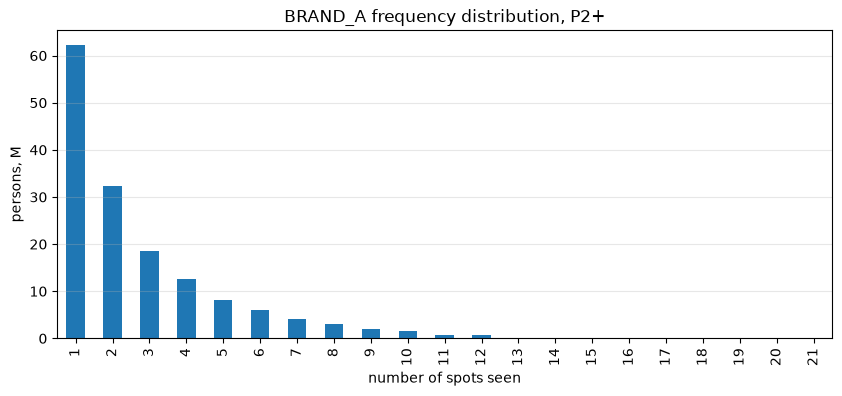

freq
1     62.2
2     32.3
3     18.5
4     12.6
5      8.1
6      6.0
7      4.1
8      3.2
9      2.0
10     1.5
11     0.7
12     0.7
13     0.2
14     0.1
15     0.1
16     0.0
17     0.0
18     0.0
19     0.0
20     0.0
21     0.1
Share of reached who saw 1 spot: 0.409
Share of reached with 5+ exposures: 0.175
Median frequency (weighted): 2
Share of impressions at 5+ exposures: 0.444


In [9]:
freq = exp.groupby("respondent_id").size()
persons["freq"] = freq.reindex(persons.index).fillna(0).astype(int)
reached = persons[persons.freq > 0]
dist = reached.groupby("freq").mw.sum() / 1e6
dist = dist.reindex(range(1, dist.index.max() + 1), fill_value=0)

dist.plot.bar(figsize=(10, 4))
plt.xlabel("number of spots seen")
plt.ylabel("persons, M")
plt.title("BRAND_A frequency distribution, P2+")
plt.grid(alpha=0.3, axis="y")
plt.show()

print(dist.round(1).to_string())
exp["freq"] = exp.respondent_id.map(freq)
share5 = exp[exp.freq >= 5].weight.sum() / exp.weight.sum()
cum = reached.sort_values("freq").mw.cumsum() / reached.mw.sum()
median_f = reached.sort_values("freq").freq[cum >= 0.5].iloc[0]
print("Share of reached who saw 1 spot:", round(reached[reached.freq == 1].mw.sum() / reached.mw.sum(), 3))
print("Share of reached with 5+ exposures:", round(reached[reached.freq >= 5].mw.sum() / reached.mw.sum(), 3))
print("Median frequency (weighted):", median_f)
print("Share of impressions at 5+ exposures:", round(share5, 3))

**Answer:** The distribution is very skewed. The biggest group is people who saw only 1 spot: 62.2 M, or 40.9% of the reached people. The weighted median is 2. Then the curve goes down slowly and has a long tail up to 21 spots. Only 17.5% of the reached people saw 5 or more spots, but they got 44.4% of all impressions. So the average frequency of 3.0 is not a fair summary. A typical viewer saw 1 or 2 spots, and a small group of heavy viewers saw the ad many times and pulls the mean up. It is better to show the distribution, or at least the median and the share of impressions at 5+.

## Task 2.3 — On target?

In [10]:
target_pop = persons[persons.a1849].mw.sum() / persons.mw.sum()
on_target = ba.imp_1849.sum() / ba.imp.sum()
print("A18-49 share of all persons:", round(target_pop, 3))
print("Share of impressions on A18-49:", round(on_target, 3))

by_net = ba.groupby("network_code")[["imp", "imp_1849"]].sum()
by_net["A18-49 share"] = by_net.imp_1849 / by_net.imp
by_net["index"] = by_net["A18-49 share"] / target_pop * 100
by_net["imp"] = by_net.imp / 1e6
by_net["imp_1849"] = by_net.imp_1849 / 1e6
by_net.columns = ["P2+ imp (M)", "A18-49 imp (M)", "A18-49 share", "index"]
by_net.sort_values("index").round(3)

A18-49 share of all persons: 0.422
Share of impressions on A18-49: 0.194


,P2+ imp (M),A18-49 imp (M),A18-49 share,index
network_code,,,,
FNC,57.799,2.717,0.047,11.148
CBS,88.980,13.693,0.154,36.495
ABC,94.211,16.989,0.180,42.764
NBC,41.435,7.834,0.189,44.833
HIST,12.329,2.485,0.202,47.792
FOX,76.256,18.440,0.242,57.346
HGTV,24.657,7.554,0.306,72.655
FOOD,9.481,2.992,0.316,74.831
BRAVO,5.084,2.817,0.554,131.410


**Answer:** Only 19.4% of the impressions went to A18-49, but A18-49 is 42.2% of all persons. So the index is about 46, and the plan delivered less than half of the fair share to the people it was bought for. That is why the A18-49 frequency is only 2.0, compared with 3.0 for P2+. The main reason is FNC: it had the most spots (40) and 57.8 M impressions, but only 4.7% of them were A18-49 (index 11). CBS, ABC and NBC also have old audiences in the dayparts used (news, daytime, mornings), with index 36-45. Only FX (index 154) and Bravo (131) over-deliver the target, but together they give only 13.6 M of 418.8 M impressions.

## Task 3.1 — Cost

In [11]:
cost = ba.cost.sum()
print("Campaign cost (USD):", round(cost))
print("P2+ CPM (USD):", round(cost / ba.imp.sum() * 1000, 2))
print("P2+ CPP (USD):", round(cost / grp))
print("A18-49 CPM (USD):", round(cost / ba.imp_1849.sum() * 1000, 2))
print("A18-49 CPP (USD):", round(cost / grp_1849))

Campaign cost (USD): 7420270
P2+ CPM (USD): 17.72
P2+ CPP (USD): 56221
A18-49 CPM (USD): 91.53
A18-49 CPP (USD): 122836


## Task 3.2 — By network

In [12]:
net = ba.groupby("network_code").agg(spots=("ad_airing_id", "size"), cost=("cost", "sum"),
                                     imp=("imp", "sum"), imp_1849=("imp_1849", "sum"))
net["cost share"] = net.cost / net.cost.sum()
net["P2+ CPM"] = net.cost / net.imp * 1000
net["A18-49 CPM"] = net.cost / net.imp_1849 * 1000
net["imp"] = net.imp / 1e6
net["imp_1849"] = net.imp_1849 / 1e6
net = net.rename(columns={"imp": "P2+ imp (M)", "imp_1849": "A18-49 imp (M)"})
net.sort_values("A18-49 CPM").round(2)

,spots,cost,P2+ imp (M),A18-49 imp (M),cost share,P2+ CPM,A18-49 CPM
network_code,,,,,,,
FX,38,92200.0,8.52,5.55,0.01,10.82,16.61
BRAVO,33,49610.0,5.08,2.82,0.01,9.76,17.61
HGTV,39,230000.0,24.66,7.55,0.03,9.33,30.45
HIST,37,79640.0,12.33,2.48,0.01,6.46,32.05
FOOD,33,96620.0,9.48,2.99,0.01,10.19,32.29
ABC,29,1625700.0,94.21,16.99,0.22,17.26,95.69
NBC,16,796800.0,41.44,7.83,0.11,19.23,101.72
CBS,22,1488700.0,88.98,13.69,0.20,16.73,108.72
FOX,13,2434700.0,76.26,18.44,0.33,31.93,132.03


In [13]:
# where did the money go inside the networks? top selling dayparts by cost
dp = ba.groupby(["network_code", "daypart", "row_kind"]).agg(spots=("ad_airing_id", "size"),
                                                             price_30s=("cost_30s_usd", "first"),
                                                             cost=("cost", "sum"))
dp["cost share"] = dp.cost / cost
dp.sort_values("cost", ascending=False).head(8).round(3)

spots  price_30s  \
network_code daypart                       row_kind                     
FOX          MLB Postseason & World Series program       4     330200   
ABC          College Football              program       7     111100   
FOX          College Football              program       4     136800   
CBS          NFL on CBS                    program       2     222600   
             Prime                         time          2     178800   
ABC          Weekend Prime                 time          2     173800   
FOX          NFL on FOX                    program       2     173600   
NBC          Prime                         time          2     173400   

                                                          cost  cost share  
network_code daypart                       row_kind                         
FOX          MLB Postseason & World Series program   1320800.0       0.178  
ABC          College Football              program    777700.0       0.105  
FOX          College Football              program    547200.0       0.074  
CBS          NFL on CBS                    program    445200.0       0.060  
             Prime                         time       357600.0       0.048  
ABC          Weekend Prime                 time       347600.0       0.047  
FOX          NFL on FOX                    program    347200.0       0.047  
NBC          Prime                         time       346800.0       0.047

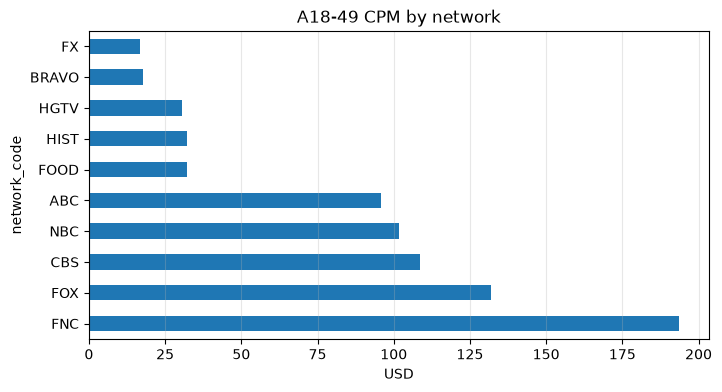

In [14]:
net["A18-49 CPM"].sort_values().plot.barh(figsize=(8, 4))
plt.gca().invert_yaxis()
plt.xlabel("USD")
plt.title("A18-49 CPM by network")
plt.grid(alpha=0.3, axis="x")
plt.show()

**Answer:** Most of the money went to the four broadcast networks: FOX 33% (only 13 spots, but 10 of them were sports sold by program rows, and the 4 MLB Postseason spots at 330,200 USD each are 18% of the whole budget alone), ABC 22% (7 College Football spots), CBS 20% and NBC 11%. FNC got 7%, and all five small networks together only 7.4% (548,070 USD), although they had 180 of the 300 spots. The cheapest ways to reach A18-49 were FX (16.61 USD CPM) and Bravo (17.61), then HGTV, HIST and FOOD (about 30-32). The broadcast networks cost 96-132 USD per thousand target impressions, so they are 6-8 times more expensive. FNC is the worst for the target, at 193.70, but it has one of the lowest P2+ CPMs (9.11): its spots are cheap, but almost all its viewers are older than 49. Note: the small-network CPMs come from few panelists, so they are less precise (see Task 5).

## Task 3.3 — Guarantee

In [15]:
owed = max(0, 150 - grp)
print("Guarantee met:", grp >= 150)
print("Make-good GRPs owed:", round(owed, 1))
print("Value of make-goods (USD):", round(owed * cost / grp))

Guarantee met: False
Make-good GRPs owed: 18.0
Value of make-goods (USD): 1012869


## Task 4 — Do networks add up?

In [16]:
r_big = reach(exp[exp.network_code.isin(BIG)])
r_small = reach(exp[exp.network_code.isin(SMALL)])
r_all = reach(exp)
overlap = r_big + r_small - r_all
cost_big = ba[ba.network_code.isin(BIG)].cost.sum()
cost_small = ba[ba.network_code.isin(SMALL)].cost.sum()

print("Reach, big networks (%):", round(r_big, 1))
print("Reach, small networks (%):", round(r_small, 1))
print("Reach, whole campaign (%):", round(r_all, 1))
print("Overlap (%):", round(overlap, 1))
print("Overlap if independent (%):", round(r_big * r_small / 100, 1))
print("Reach added by small networks (points):", round(r_all - r_big, 1))
print("Cost per added reach point, small (USD):", round(cost_small / (r_all - r_big)))
print("Cost per reach point, big (USD):", round(cost_big / r_big))

Reach, big networks (%): 39.8
Reach, small networks (%): 12.4
Reach, whole campaign (%): 43.5
Overlap (%): 8.7
Overlap if independent (%): 4.9
Reach added by small networks (points): 3.7
Cost per added reach point, small (USD): 148706
Cost per reach point, big (USD): 172456


In [17]:
print("Big-network reach among small-network viewers (%):", round(overlap / r_small * 100, 1))
print("Small-network spend (USD):", round(cost_small), " share:", round(cost_small / cost, 3))

# who are the people the small networks added (reached by small only)?
ids_big = set(exp[exp.network_code.isin(BIG)].respondent_id)
ids_small = set(exp[exp.network_code.isin(SMALL)].respondent_id)
added = persons[persons.index.isin(ids_small - ids_big)]
reached_all = persons[persons.index.isin(ids_big | ids_small)]
print("A18-49 share, added by small only:", round(added[added.a1849].mw.sum() / added.mw.sum(), 3))
print("A18-49 share, all reached:", round(reached_all[reached_all.a1849].mw.sum() / reached_all.mw.sum(), 3))
r1849_big = reach(exp[exp.network_code.isin(BIG)], "a1849")
print("A18-49 reach, big only / whole (%):", round(r1849_big, 1), round(reach_1849, 1))
print("A18-49 reach added by small (points):", round(reach_1849 - r1849_big, 1))

Big-network reach among small-network viewers (%): 70.2
Small-network spend (USD): 548070  share: 0.074
A18-49 share, added by small only: 0.593
A18-49 share, all reached: 0.295
A18-49 reach, big only / whole (%): 25.3 30.5
A18-49 reach added by small (points): 5.2


In [18]:
# heavy viewers? minutes per in-tab day on the 10 networks
mins = ((pv.end_ts - pv.start_ts).dt.total_seconds() / 60).groupby(pv.respondent_id).sum()
mins = mins.reindex(persons.index).fillna(0) / pw.groupby("respondent_id").size()
groups = {"all persons": persons.index, "reached by big": list(ids_big), "reached by small": list(ids_small),
          "not reached": persons.index.difference(list(ids_big | ids_small))}
tmp = {g: np.average(mins[mins.index.isin(ids)], weights=persons.mw[persons.index.isin(ids)])
       for g, ids in groups.items()}
pd.Series(tmp, name="viewing min / day").round(1)

all persons          56.8
reached by big      112.0
reached by small    124.1
not reached          18.5
Name: viewing min / day, dtype: float64

**Answer:** Big networks alone reach 39.8% and small networks alone reach 12.4%. The sum is 52.2%, but the whole campaign reaches only 43.5%. Reach counts unique people, and 8.7% of the population saw spots on both groups, so in the sum they are counted twice (inclusion-exclusion: 39.8 + 12.4 - 8.7 = 43.5). If the two audiences were independent, the overlap would be 39.8% x 12.4% = 4.9%. The real overlap is 8.7%, about 1.8 times more. Among people reached by the small networks, 70.2% were also reached by the big ones, but in the whole population this is only 39.8%. So small-network viewers are more likely than average to be reached by the big networks. I think the reason is that they are heavy TV viewers, and the table above shows it: people reached by the small networks watch these 10 networks about 124 min per day, people reached by the big ones 112, the average person 57 and the people not reached only 18.5. A heavy viewer watches many networks, so they are easy to catch twice, and a light viewer watches almost nothing and is missed by both groups. The small networks added 3.7 reach points for 548,070 USD, which is 148,706 USD per added point. On the big networks one reach point cost 172,456 USD on average. So the added points were even a bit cheaper, and they are the right people: 59% of the people added only by the small networks are A18-49, against 30% of everybody reached. In the target the small networks added 5.2 points of A18-49 reach (25.3% to 30.5%). So I think this money was well spent, only the reach numbers of the small networks stand on few panelists (Task 5).

## Task 5 — How sure are we?

In [19]:
ba["panelists"] = ba.ad_airing_id.map(exp.groupby("ad_airing_id").size()).fillna(0).astype(int)
ba["n"] = ba.bday.map(day_n)
p = ba.rating / 100
ba["se"] = np.sqrt(p * (1 - p) / ba.n) * 100
ba["rel_se"] = ba.se / ba.rating
# rating 0 -> SE 0 and 0/0 = NaN; median() would just drop these spots, but they are the
# least precise ones, so count them as infinite relative error instead
ba.loc[ba.rating == 0, "rel_se"] = np.inf
ba["w1834_seen"] = ba.ad_airing_id.map(exp[exp.w1834].groupby("ad_airing_id").size()).fillna(0)
ba["group"] = np.where(ba.network_code.isin(BIG), "big", "small")

quality = ba.groupby(["group", "network_code"]).agg(
    spots=("ad_airing_id", "size"),
    median_panelists=("panelists", "median"),
    zero_panelists=("panelists", lambda x: (x == 0).sum()),
    median_rating=("rating", "median"),
    median_rel_se=("rel_se", "median"),
)
print(quality.round(3))

print("Spots seen by no panelist:", (ba.panelists == 0).sum())
print("Rating of those spots:", ba[ba.panelists == 0].rating.max())
print("Median relative SE, big networks:", round(ba[ba.group == "big"].rel_se.median(), 3))
print("Median relative SE, small networks:", round(ba[ba.group == "small"].rel_se.median(), 3))
print("W18-34 zero-cell spots:", (ba.w1834_seen == 0).sum())

                    spots  median_panelists  zero_panelists  median_rating  \
group network_code                                                           
big   ABC              29              57.0               0          0.714   
      CBS              22              69.0               0          0.844   
      FNC              40              31.0               0          0.399   
      FOX              13             145.0               0          1.641   
      NBC              16              68.5               0          0.811   
small BRAVO            33               3.0               3          0.025   
      FOOD             33               5.0               2          0.056   
      FX               38               5.5               4          0.055   
      HGTV             39              11.0               0          0.119   
      HIST             37               5.0               1          0.050   

                    median_rel_se  
group network_code         

In [20]:
print("Panelists in-tab per day, median:", day_n.median())
print("Persons per panelist, median day:", round((day_p2 / day_n).median()))
print("Median relative SE, small, without zero spots:",
      round(ba[(ba.group == "small") & (ba.rating > 0)].rel_se.median(), 3))
# weighting: Kish effective sample size n_eff = (sum w)^2 / sum w^2
n_eff = pw.groupby("bday").weight.apply(lambda w: w.sum() ** 2 / (w ** 2).sum())
print("Effective n per day, median:", round(n_eff.median()), " design effect:", round((day_n / n_eff).median(), 3))
print("W18-34 panelists in-tab per day, median:", pw[pw.w1834].groupby("bday").size().median())
print("Spots seen by 1-4 panelists:", ba.panelists.between(1, 4).sum())
print(ba.groupby("group").w1834_seen.agg(lambda x: (x == 0).mean()).round(3).rename("W18-34 zero-cell share"))

Panelists in-tab per day, median: 9264.0
Persons per panelist, median day: 34248
Median relative SE, small, without zero spots: 0.417
Effective n per day, median: 8647  design effect: 1.072
W18-34 panelists in-tab per day, median: 953.0
Spots seen by 1-4 panelists: 64
group
big      0.45
small    0.65
Name: W18-34 zero-cell share, dtype: float64


**Answer:** On the big networks the median spot was seen by 31 (FNC) to 145 (FOX) panelists. On the small networks it was only 3 to 11 panelists. 10 spots, all on small networks (FX 4, Bravo 3, FOOD 2, HIST 1), were seen by no panelist, so their rating is exactly 0.0. This does not mean nobody saw the ad. About 9,260 persons are in-tab per day, so one panelist stands for about 34,000 people (a rating of about 0.01). Any audience smaller than this can easily give zero panelists. Another 64 spots were seen by only 1-4 panelists. The median relative standard error is 0.122 on the big networks and 0.431 on the small ones. For the 10 zero spots the formula gives SE = 0 and the relative error is 0/0, so I counted them as infinite error and not as perfectly precise; if they are just dropped, the small-network median is 0.417, which looks a bit better than it is. So a small-network spot rating is known only to about ±40% (Bravo ±65%), and for small networks it is better to read ratings summed over a month than spot by spot. The real error is even larger because of weighting: the Kish effective sample is about 8,650 instead of 9,264 (design effect 1.07), so the SE grows by about 3.5%. This is small here, but the formula still assumes simple random sampling, so it is a lower bound. For W18-34, 171 of the 300 spots are zero-cells (45% on big networks, 65% on small). Only about 950 women 18-34 are in-tab per day. If the client asked for the W18-34 rating by spot, I would say that we cannot report it: most spots would show 0, and the others rest on one or two women. I would give W18-34 numbers only for bigger groups of spots, for example the whole campaign, or by network or daypart over the month.

## Bonus

In [21]:
cell = ba.groupby(["network_code", "daypart"]).agg(spots=("ad_airing_id", "size"), cost=("cost", "sum"),
                                                   imp_1849=("imp_1849", "sum"))
cell["A18-49 CPM"] = cell.cost / cell.imp_1849 * 1000
cell = cell.sort_values("A18-49 CPM")
print(cell.round(2))

                                            spots       cost   imp_1849  \
network_code daypart                                                      
HGTV         Late Night & Overnight             4     1800.0   490285.0   
FOOD         Late & Overnight                   2      620.0   158815.0   
BRAVO        Early Fringe                       1     2100.0   254465.0   
FX           Daytime Movies                    25    27500.0  2311756.0   
HGTV         Early Fringe                       4    17600.0  1463922.0   
BRAVO        Weekend Marathon                   6     5220.0   412179.0   
FX           Late Night                         2     2200.0   171468.0   
BRAVO        Late Fringe                        9     7830.0   512173.0   
             Daytime Rotator                   12     6960.0   415604.0   
FX           Fringe                             5    14500.0   724736.0   
             Prime                              6    48000.0  2343170.0   
BRAVO        Prime       

In [22]:
cell["P2+ imp"] = ba.groupby(["network_code", "daypart"]).imp.sum()
ba2 = ba.merge(cell[["A18-49 CPM"]].reset_index(), on=["network_code", "daypart"])
moved = ba2.sort_values("A18-49 CPM", ascending=False).head(20)
budget = moved.cost.sum()

new_imp_1849 = 0
new_imp_p2 = 0
for target in [("FX", "Prime"), ("HGTV", "Prime")]:
    c = cell.loc[target]
    new_imp_1849 += budget / 2 / c.cost * c.imp_1849
    new_imp_p2 += budget / 2 / c.cost * c["P2+ imp"]
    print(target, "spots bought:", round(budget / 2 / (c.cost / c.spots)))

imp_1849_after = ba.imp_1849.sum() - moved.imp_1849.sum() + new_imp_1849
imp_p2_after = ba.imp.sum() - moved.imp.sum() + new_imp_p2
print("Moved spots:", moved.groupby(["network_code", "daypart"]).size().to_dict())
print("Moved budget (USD):", round(budget))
print("A18-49 impressions, moved spots (M):", round(moved.imp_1849.sum() / 1e6, 1))
print("A18-49 impressions, new spots (M):", round(new_imp_1849 / 1e6, 1))
print("A18-49 CPM before (USD):", round(cost / ba.imp_1849.sum() * 1000, 2))
print("A18-49 CPM after (USD):", round(cost / imp_1849_after * 1000, 2))
print("P2+ impressions before / after (M):", round(ba.imp.sum() / 1e6, 1), round(imp_p2_after / 1e6, 1))
print("Moved spots seen by panelists, median:", moved.panelists.median())

('FX', 'Prime') spots bought: 44
('HGTV', 'Prime') spots bought: 27
Moved spots: {('CBS', 'Daytime'): 4, ('FNC', 'Daytime News'): 9, ('FNC', 'Early Evening'): 3, ('FNC', 'Prime Opinion'): 2, ('NBC', 'Prime'): 2}
Moved budget (USD): 707800
A18-49 impressions, moved spots (M): 1.9
A18-49 impressions, new spots (M): 26.7
A18-49 CPM before (USD): 91.53
A18-49 CPM after (USD): 70.07
P2+ impressions before / after (M): 418.8 433.7
Moved spots seen by panelists, median: 45.0


**Answer:** I would move the 20 spots from the network-dayparts with the highest A18-49 CPM (FNC Daytime News 9, FNC Early Evening 3, FNC Prime Opinion 2, CBS Daytime 4, NBC Prime 2). Together they cost 707,800 USD but delivered only 1.9 M A18-49 impressions. I would spend this money half on FX Prime and half on HGTV Prime (about 44 + 27 spots at their CPMs of 20.49 and 37.38 USD), which should give about 26.7 M A18-49 impressions. Then the campaign A18-49 CPM goes down from 91.53 to about 70.07 USD, and P2+ impressions even go up a little (418.8 to 433.7 M), so the P2+ guarantee also gets about 5 GRPs closer. This is only an estimate from few spots (6 on FX Prime, 14 on HGTV Prime), so it is better to split the new spots over more young-skewing cable dayparts (FX, Bravo, HGTV) so that the frequency does not grow too much on one network.